# Домашнє завдання 3 · Ознаки, аутлаєри та ICP
**Заняття 3 · OpenCV + Open3D · ≈ 2 години**

Дві частини, по одній на кожен спосіб оцінки руху з лекції. У дужках — назви слайдів, де пояснено теорію кроку.

| Частина | Що робимо | Слайди | Дані |
|---|---|---|---|
| **1 · 2D-2D** | ORB → зіставлення + ratio test → RANSAC і Essential matrix → поворот R і напрямок t | «Виявлення та зіставлення ознак» … «Як вирішують проблему масштабу на практиці?» | два кадри з набору Fountain + GT-пози камери (~33 МБ) |
| **2 · 3D-3D** | voxel downsampling → ICP з початковим наближенням і без нього → зшиті скани | «Підготовка хмари: вокселі й нормалі», «Метод 3D-to-3D», «ICP: як це працює», «ICP: поріг відповідностей і метрики» | два скани вітальні Redwood (~17 МБ) |

```
Частина 1:  кадр A, кадр B ──► ORB ──► knn + ratio test ──► RANSAC → E ──► recoverPose → R, t ──► порівняння з GT
Частина 2:  скан 1, скан 2 ──► voxel ──► ICP (старт від «IMU») ──► ICP без старту ──► зшита хмара .ply
```

**Як працювати.** Завантаження, візуалізацію та перевірки вже написано. Вам лишається вписати там, де стоїть `TODO`, **один виклик функції OpenCV/Open3D або значення параметра**. Формул писати не треба. Після кожного кроку є клітинка `check(...)`: ✅ означає, що крок виконано, ❌ — що треба ще покрутити (підказка завжди поруч).

**Що здати** — прикріпіть в особистому кабінеті LMS:
1. цей ноутбук **з виводами** (Kernel → Restart & Run All, потім зберегти), заповнені таблиці й відповіді в клітинках «✍️» (по 1–3 речення, своїми словами);
2. файл `outputs/room_merged.ply` (з'явиться поруч із ноутбуком після кроку 2.6).

**Середовище.** Ядро **Python (cv-advanced)**: усе потрібне, зокрема `open3d`, ставить `requirements.txt` з кореня репозиторію. Open3D працює на Python 3.10–3.12. Дані (~50 МБ) Open3D завантажить сам у `~/open3d_data` під час першого запуску.

| Крок | Бали |
|---|---|
| 1.2 · ORB | 1 |
| 1.3 · зіставлення, ratio test і таблиця збігів | 2 |
| 1.4 · RANSAC і Essential matrix | 2 |
| 1.5 · поворот і напрямок руху | 2 |
| 2.2 · voxel downsampling і вибір `VOXEL` | 2 |
| 2.3 · ICP від `T_INIT`, підбір `ICP_DIST` | 3 |
| 2.4 · ICP від `eye(4)` | 1 |
| 2.6 · здано `outputs/room_merged.ply` | 1 |
| 3 · питання | 4 × 1,5 |
| **Разом** | **20** |

Крок зараховано, якщо його `check()` дає ✅. Бонус не оцінюється.

In [155]:
from pathlib import Path
import time
import numpy as np
import cv2
import matplotlib.pyplot as plt
import open3d as o3d

o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
OUT_DIR = Path('outputs'); OUT_DIR.mkdir(exist_ok=True)

# Вікно Open3D зручніше (можна крутити мишею), але інколи не відкривається в Jupyter.
# False — картинки малює matplotlib прямо в ноутбуці (так їх побачить і викладач).
OPEN3D_WINDOW = False


def show_cloud(*clouds, title='', max_points=40_000, views=((20, -60), (75, -90))):
    # Показує одну чи кілька хмар точок. Колір — з хмари (якщо він є).
    if OPEN3D_WINDOW:
        o3d.visualization.draw_geometries(list(clouds), window_name=title)
        return
    
    # Отримання координат та кольорів    
    pts = np.vstack([np.asarray(c.points) for c in clouds])
    cols = np.vstack([np.asarray(c.colors) if c.has_colors() else np.full((len(c.points), 3), 0.4) for c in clouds])
    
    if len(pts) > max_points:
        idx = np.random.default_rng(0).choice(len(pts), max_points, replace=False)
        pts, cols = pts[idx], cols[idx]
    
    # у камери вісь Y дивиться вниз — перевертаємо для зручного перегляду 3D-сцени
    x, y, z = pts[:, 0], pts[:, 2], -pts[:, 1]         
    
    fig = plt.figure(figsize=(6 * len(views), 4.8))
    for k, (elev, azim) in enumerate(views):
        ax = fig.add_subplot(1, len(views), k + 1, projection='3d')
        ax.scatter(x, y, z, c=np.clip(cols, 0, 1), s=1.0, linewidths=0)
        ax.view_init(elev, azim); ax.set_axis_off(); ax.set_box_aspect((np.ptp(x), np.ptp(y), np.ptp(z)), zoom=1.6)
    fig.suptitle(title); fig.subplots_adjust(0, 0, 1, 0.94, 0, 0); plt.show()


def show_images(*imgs, titles=(), size=6):
    fig, axes = plt.subplots(1, len(imgs), figsize=(size * len(imgs), size * 0.75))
    for ax, im, t in zip(np.atleast_1d(axes), imgs, list(titles) + [''] * len(imgs)):
        ax.imshow(im, cmap='gray' if im.ndim == 2 else None); ax.set_title(t); ax.axis('off')
    plt.tight_layout(); plt.show()


def check(ok, good, bad):
    print(('✅ ' + good) if ok else ('❌ ' + bad))
    return ok

# задати колір хмарі
def paint(cloud, rgb):
    c = o3d.geometry.PointCloud(cloud); c.paint_uniform_color(rgb); return c

def rot_deg(R):
    # кут повороту матриці R, градуси
    return np.degrees(np.arccos(np.clip((np.trace(R) - 1) / 2, -1, 1)))

def angle_deg(a, b):
    # кут між двома векторами, градуси
    a, b = np.ravel(a), np.ravel(b)
    return np.degrees(np.arccos(np.clip(a @ b / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1)))

# Частина 1 · Ознаки та оцінка руху 2D-2D

## 1.1 · Дані (≈ 5 хв)
Камера знімала фонтан, обходячи його. Беремо два кадри: між ними камера повернулась приблизно на 10° і зсунулась на 15 см. Для кожного кадру відома справжня поза (ground truth), тож ми зможемо перевірити, наскільки точно відновили рух.

Матриця камери `K` відома з калібрування (заняття 2). Тому працюємо з **Essential matrix** (слайд «Метод 2D-to-2D: монокулярна VO»), а не з Fundamental.

In [158]:
# Завантаження набору
fountain = o3d.data.SampleFountainRGBDImages()

# Завантаження справжніх поз камери:
traj = o3d.io.read_pinhole_camera_trajectory(
    # шлях до файлу з позами ключових кадрів.
    fountain.keyframe_poses_log_path
)

In [160]:
print(type(traj))

<class 'open3d.cpu.pybind.camera.PinholeCameraTrajectory'>


In [162]:
print(traj.parameters[0])

PinholeCameraParameters class.
Access its data via intrinsic and extrinsic.


pose має тип PinholeCameraParameters. Його основні дані доступні через два атрибути: intrinsic та extrinsic

In [165]:
print("Кількість поз:", len(traj.parameters))

Кількість поз: 33


In [167]:
pose = traj.parameters[0]

print("=== Intrinsic ===")
print(pose.intrinsic)

print("\n=== Матриця K ===")
print(pose.intrinsic.intrinsic_matrix)

print("\n=== Extrinsic ===")
print(pose.extrinsic)

=== Intrinsic ===
PinholeCameraIntrinsic(width=640, height=480, )

=== Матриця K ===
[[525.    0.  319.5]
 [  0.  525.  239.5]
 [  0.    0.    1. ]]

=== Extrinsic ===
[[ 0.99992596 -0.01208015 -0.00105007 -0.72907554]
 [ 0.01207743  0.99992339 -0.00259535 -0.75162931]
 [ 0.00108134  0.00258247  0.99999516  0.32093564]
 [-0.          0.          0.          1.        ]]


У контексті Visual Odometry: intrinsic потрібен для геометричних обчислень із зображеннями, а extrinsic дозволяє дослідити позу камери. В Open3D extrinsic зазвичай перетворює координати зі світової системи в систему координат камери.

In [170]:
# калібрування камери PrimeSense
K = np.array([
    [525.0, 0, 319.5], 
    [0, 525.0, 239.5], 
    [0, 0, 1]
])

# Матриця K потрібна для зв'язку між просторовими напрямками та піксельними координатами.

# K = [
#     [f_x,  0,  c_x],
#     [0,   f_y, c_y],
#     [0,   0,  1],
# ]
# (f_x)	525	Фокусна відстань у пікселях по горизонталі
# (f_y)	525	Фокусна відстань у пікселях по вертикалі
# (c_x)	319.5	Координата головної точки по горизонталі
# (c_y)	239.5	Координата головної точки по вертикалі

In [172]:
# вибираємо кадри з індексами 4 і 6 - номери кадрів
A, B = 4, 6
# Завантаження обох кадрів в градаціях сірого.
img_a, img_b = [cv2.imread(fountain.color_paths[i], cv2.IMREAD_GRAYSCALE) for i in (A, B)]

In [174]:
# Обчислення ground truth — справжнього руху камери

# GT: X_b = R_gt · X_a + t_gt  (точка в системі камери A → у системі камери B)
T_gt = (
    np.asarray(traj.parameters[B].extrinsic) 
    @ np.linalg.inv(
        np.asarray(traj.parameters[A].extrinsic)
    )
)
# np.linalg.inv(...) — обчислює обернену матрицю.
# @ — виконує матричне множення.

In [176]:
print(T_gt)

[[ 0.99189379 -0.08434318  0.09501852 -0.03583077]
 [ 0.09557359  0.98808834 -0.12060699  0.0648057 ]
 [-0.08371411  0.12871114  0.98814164 -0.12668601]
 [ 0.          0.          0.          1.        ]]


In [178]:
# T_gt = [
#     [r_11, r_12, r_13, t_x],
#     [r_21, r_22, r_23, t_y],
#     [r_31, r_32, r_33, t_z],
#     [0,    0,    0,    1]
# ]

In [180]:
# Відокремлення повороту та перенесення
R_gt, t_gt = T_gt[:3, :3], T_gt[:3, 3]
# T_gt[:3, :3] бере перші три рядки та перші три стовпці — матрицю повороту R_{gt}
# T_gt[:3, 3] бере перші три рядки четвертого стовпця — вектор перенесення t_{gt}

In [182]:
print("=== R_gt ===")
print(R_gt)

print("=== t_gt ===")
print(t_gt)

=== R_gt ===
[[ 0.99189379 -0.08434318  0.09501852]
 [ 0.09557359  0.98808834 -0.12060699]
 [-0.08371411  0.12871114  0.98814164]]
=== t_gt ===
[-0.03583077  0.0648057  -0.12668601]


In [184]:
print(f'GT: поворот {rot_deg(R_gt):.1f}°, зсув {np.linalg.norm(t_gt) * 100:.1f} см')

GT: поворот 10.2°, зсув 14.7 см


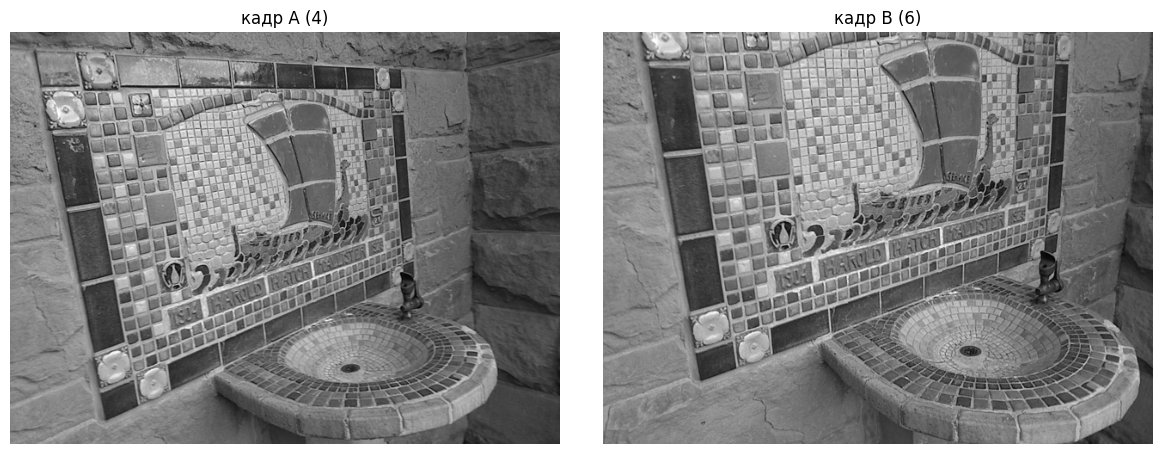

In [186]:
show_images(img_a, img_b, titles=(f'кадр A ({A})', f'кадр B ({B})'))

## 1.2 · Детекція ORB (≈ 10 хв)
ORB шукає кутоподібні точки (детектор FAST) і для кожної рахує **бінарний дескриптор**: 256 порівнянь яскравості пікселів довкола точки, тобто 32 байти (слайд «Візуальні дескриптори: математичне подання ознак»).

**TODO 1.2.** Створіть детектор ORB на 2000 точок і знайдіть точки та дескриптори на обох кадрах.

*Підказки:* `cv2.ORB_create(nfeatures=...)`; `orb.detectAndCompute(img, None)` повертає пару `(точки, дескриптори)`.

In [189]:
# створюємо детектор ORB на 2000 точок
orb = cv2.ORB_create(nfeatures=2000)              # TODO 1.2: детектор ORB на 2000 точок
# Знаходимо ключові точки та дескриптори кадрів
kp_a, des_a = orb.detectAndCompute(img_a, None)   # TODO 1.2: точки й дескриптори кадру A
kp_b, des_b = orb.detectAndCompute(img_b, None)   # TODO 1.2: те саме для кадру B

print(f'точок: A — {len(kp_a)}, B — {len(kp_b)}')
print(f'дескриптори: форма {des_a.shape}, тип {des_a.dtype} → {des_a.shape[1] * 8} біт на точку')

точок: A — 2000, B — 2000
дескриптори: форма (2000, 32), тип uint8 → 256 біт на точку


In [191]:
# kp_a — ключові точки
# Це список об'єктів cv2.KeyPoint.

print("=== kp_a ===")
print(kp_a[0].pt)       # координати (x, y)
print(kp_a[0].size)     # характерний масштаб
print(kp_a[0].angle)    # орієнтація в градусах
print(kp_a[0].response) # оцінка виразності точки


# des_a — дескриптори
# Дескриптор — це числовий опис оточення ключової точки.
# Для ORB він має довжину 256 біт — 32 байти на одну точку.
# Кожен біт кодує результат певного порівняння яскравостей пікселів у локальному оточенні точки.

=== kp_a ===
(259.0, 276.0)
31.0
219.58795166015625
0.0009813584620133042


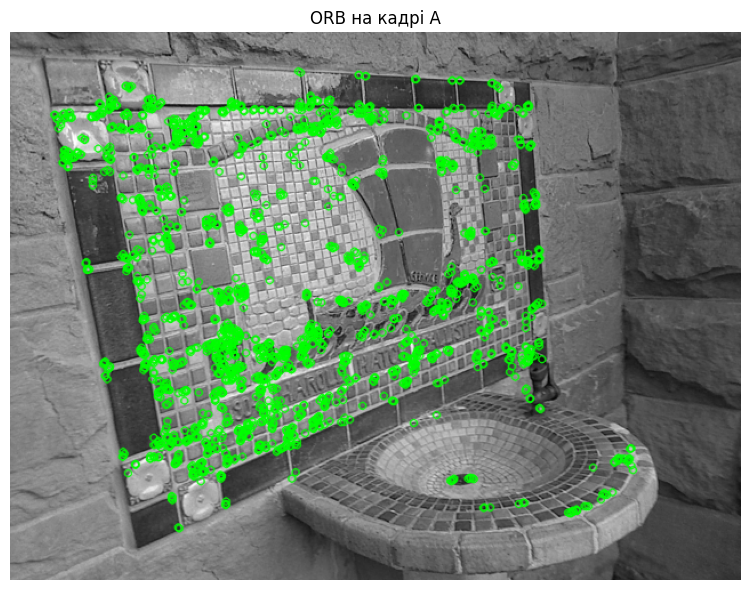

✅ ORB знайшов точки


True

In [193]:
show_images(
    cv2.drawKeypoints(
        img_a, kp_a, None, 
        color=(0, 255, 0)
    ), 
    titles=('ORB на кадрі A',), 
    size=8
)
check(len(kp_a) >= 1000 and len(kp_b) >= 1000 and des_a.dtype == np.uint8,
      'ORB знайшов точки', 'точок замало або дескриптори не ORB — перевірте nfeatures і виклик detectAndCompute')

Для порівняння — SIFT на тому самому кадрі (той самий слайд: «128-мірний вектор float»). Подивіться на час і розмір дескриптора.

In [196]:
for name, det in [('ORB', cv2.ORB_create(2000)), ('SIFT', cv2.SIFT_create(2000))]:
    t0 = time.perf_counter(); 
    _, d = det.detectAndCompute(img_a, None); 
    ms = (time.perf_counter() - t0) * 1000
    print(f'{name:>4}: {ms:6.1f} мс, дескриптор {d.shape[1]} × {d.dtype} = {d.shape[1] * d.itemsize} байт')

 ORB:   16.2 мс, дескриптор 32 × uint8 = 32 байт
SIFT:   95.6 мс, дескриптор 128 × float32 = 512 байт


✍️ **Зверніть увагу:** де на кадрі скупчились точки ORB, а де їх майже немає? (Не оцінюється — знадобиться для питань.)

## 1.3 · Зіставлення і ratio test Лоу (≈ 15 хв)
Для кожного дескриптора кадру A шукаємо **двох** найближчих сусідів у кадрі B за **відстанню Хеммінга** — кількістю різних бітів (слайд «Зіставлення ознак та робастне оцінювання»). Далі ratio test: збіг приймаємо, лише якщо найкращий сусід помітно ближчий за другого, `d₁ < ratio · d₂`. Так відсіюються неоднозначні збіги на повторюваних текстурах — а мозаїка фонтану саме така: сотні однакових плиток.

**TODO 1.3.** (а) Створіть matcher із метрикою Хеммінга і знайдіть 2 найближчих сусіди. (б) Допишіть умову ratio test.

*Підказки:* `cv2.BFMatcher(cv2.NORM_HAMMING)`; `matcher.knnMatch(des_a, des_b, k=2)`. Кожен елемент `knn` — пара `(m, n)`, де `m.distance` і `n.distance` — відстані до 1-го і 2-го сусіда.

ratio = 0.6  →   326 збігів
ratio = 0.75 →   629 збігів
ratio = 0.9  →  1041 збігів
ratio = 1.0  →  1879 збігів


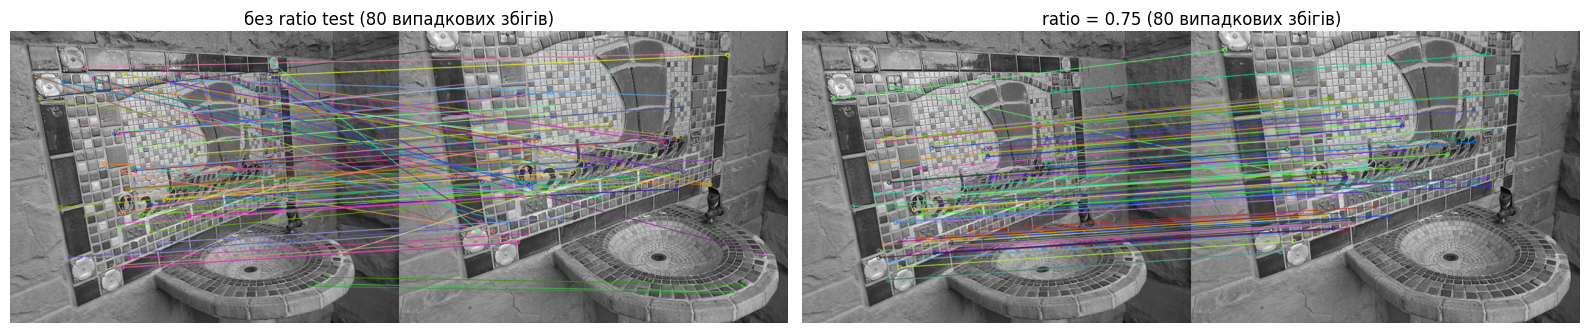

✅ 629 збігів після ratio test


True

In [199]:
# TODO 1.3а: matcher з відстанню Хеммінга
matcher = cv2.BFMatcher(cv2.NORM_HAMMING)
# TODO 1.3а: 2 найближчих сусіди для кожної точки A
knn = matcher.knnMatch(des_a, des_b, k=2)
# knn — список пар зіставлень

def ratio_test(knn, ratio):
    pairs = [p for p in knn if len(p) == 2]
    return [
        m for m, n in pairs 
        if m.distance < ratio * n.distance
    ]   # TODO 1.3б: умова Лоу


for r in [0.6, 0.75, 0.9, 1.0]:
    print(
        f'ratio = {r:<4} → {len(ratio_test(knn, r)):>5} збігів'
    )

# ratio	Умова	        Очікуваний ефект
# 0.6	(d_1<0.6d_2)	Суворий відбір, менше збігів
# 0.75	(d_1<0.75d_2)	Компроміс між кількістю та однозначністю
# 0.9	(d_1<0.9d_2)	Більше збігів, але більше неоднозначних
# 1.0	(d_1<d_2)	    Приймаються майже всі пари з різними відстанями

# значення зі слайда «Зіставлення ознак та робастне оцінювання»
RATIO = 0.75
good = ratio_test(knn, RATIO)
# список good — відповідності між ключовими точками кадрів A і B, які пройшли ratio test

rng = np.random.default_rng(0)
sample = lambda ms: list(rng.choice(ms, min(80, len(ms)), replace=False))
flags = cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
show_images(cv2.drawMatches(img_a, kp_a, img_b, kp_b, sample(ratio_test(knn, 1.0)), None, flags=flags),
            cv2.drawMatches(img_a, kp_a, img_b, kp_b, sample(good), None, flags=flags),
            titles=('без ratio test (80 випадкових збігів)', f'ratio = {RATIO} (80 випадкових збігів)'), size=8)
check(300 <= len(good) < len(ratio_test(knn, 1.0)), f'{len(good)} збігів після ratio test',
      f'{len(good)} збігів — перевірте умову: найкращий сусід має бути ближчим за ratio × другий')

✍️ **Заповніть таблицю** (числа з виводу):

| ratio | збігів |
|---|---|
| 0.6 | 326|
| 0.75 | 629|
| 0.9 | 1041|
| 1.0 (без тесту) | 1879 |

## 1.4 · RANSAC і Essential matrix (≈ 15 хв)
Навіть після ratio test частина збігів хибна. `findEssentialMat` запускає RANSAC (слайд «RANSAC проти найменших квадратів»): багато разів бере 5 випадкових пар, рахує E алгоритмом Ністера і перевіряє, скільки інших пар задовольняють епіполярне обмеження з точністю до порогу в пікселях. Перемагає E з найбільшою кількістю інлаєрів, а `mask` позначає, які пари вони.

**TODO 1.4.** Оцініть E з RANSAC: ймовірність `0.999`, поріг `1.0` пікселя.

*Підказка:* `cv2.findEssentialMat(pts_a, pts_b, K, cv2.RANSAC, 0.999, 1.0)` повертає `(E, mask)`.

In [130]:
pts_a = np.float32([kp_a[m.queryIdx].pt for m in good])
pts_b = np.float32([kp_b[m.trainIdx].pt for m in good])

In [132]:
print(pts_a)

[[200.      263.     ]
 [201.      233.     ]
 [205.      231.     ]
 ...
 [118.245   250.82272]
 [189.90865 336.8191 ]
 [164.82637 315.32   ]]


In [134]:
# TODO 1.4: E з RANSAC
E, mask = cv2.findEssentialMat(
    pts_a,
    pts_b,
    K,
    cv2.RANSAC,
    0.999,
    1.0
)
inl = mask.ravel().astype(bool)
print(f'інлаєрів {inl.sum()} з {len(inl)} ({inl.mean():.0%}), аутлаєрів {(~inl).sum()}')

інлаєрів 469 з 629 (75%), аутлаєрів 160


Як працює RANSAC?
1. Випадково вибирає мінімальну кількість відповідностей для оцінювання моделі. Для п'ятиточкового алгоритму Essential matrix це п'ять пар.
2. Обчислює кандидата на Essential matrix.
3. Перевіряє, наскільки інші відповідності узгоджуються з моделлю.
4. Повторює процедуру для інших вибірок.
5. Вибирає модель, що має достатню підтримку відповідностей.

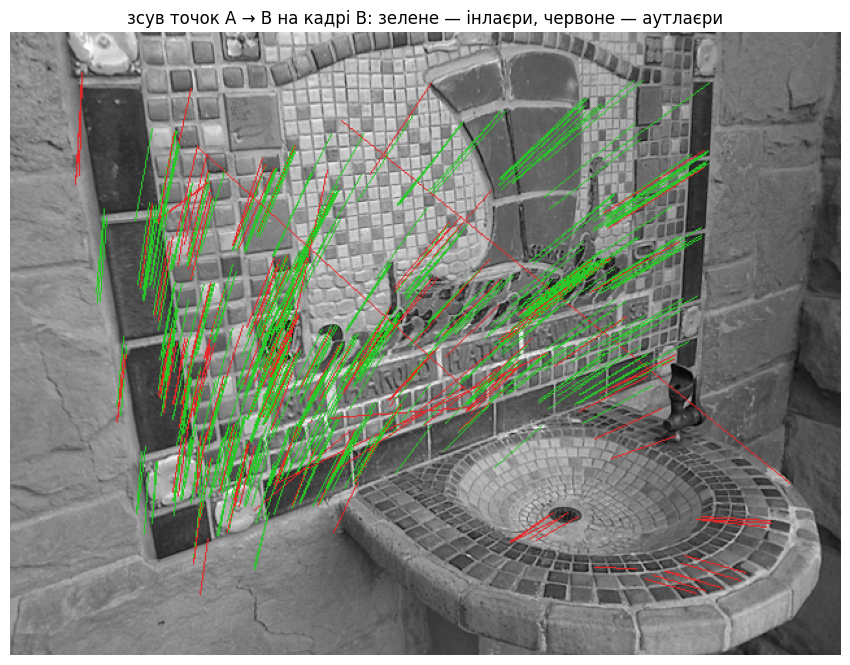

✅ E знайдено, інлаєрів 75%


np.True_

In [137]:
vis = cv2.cvtColor(img_b, cv2.COLOR_GRAY2RGB)
for (xa, ya), (xb, yb), ok in zip(pts_a, pts_b, inl):
    cv2.line(
        vis, 
        (int(xa), int(ya)), 
        (int(xb), int(yb)), 
        (40, 200, 40) if ok else (230, 40, 40), 
        1
    )
show_images(vis, titles=('зсув точок A → B на кадрі B: зелене — інлаєри, червоне — аутлаєри',), size=9)
check(E is not None and E.shape == (3, 3) and inl.mean() >= 0.5, f'E знайдено, інлаєрів {inl.mean():.0%}',
      'E не знайдено або інлаєрів менше 50 % — перевірте аргументи findEssentialMat')

## 1.5 · Поворот і напрямок руху (≈ 10 хв)
E розкладається через SVD на 4 варіанти `[R|t]`, і лише в одному точки лежать **перед** обома камерами (cheirality check, слайд «Метод 2D-to-2D: алгоритм обчислення зміщення»). Усе це робить `recoverPose`.

**TODO 1.5.** Відновіть R і t з E (тільки на інлаєрах, тому передайте `mask`).

*Підказка:* `cv2.recoverPose(E, pts_a, pts_b, K, mask=mask)` повертає `(кількість_точок, R, t, mask)`.

In [140]:
print("img_a:", img_a.shape)
print("img_b:", img_b.shape)
print("K:\n", K)

img_a: (480, 640)
img_b: (480, 640)
K:
 [[525.    0.  319.5]
 [  0.  525.  239.5]
 [  0.    0.    1. ]]


In [142]:
# TODO 1.5: R і t з E
_, R, t, _ = cv2.recoverPose(
    E,
    pts_a,
    pts_b,
    K,
    mask=mask
)

In [144]:
print("=== R ===")
print(R)
print("=== t ===")
print(t)

=== R ===
[[ 0.99790811 -0.06417076 -0.00784359]
 [ 0.0634503   0.99542903 -0.07138001]
 [ 0.01238824  0.07073302  0.99741835]]
=== t ===
[[ 0.59380956]
 [-0.03690699]
 [-0.80375872]]


In [146]:
rot_err, dir_err = rot_deg(R.T @ R_gt), angle_deg(t, t_gt)

# rot_err порівнює оцінений поворот із ground truth.
# dir_err порівнює напрямки t і t_gt.

print(f'поворот:  оцінка {rot_deg(R):5.2f}°,  GT {rot_deg(R_gt):5.2f}°,  похибка {rot_err:.2f}°')
print(f'напрямок зсуву: похибка {dir_err:.1f}°')
print(f'довжина зсуву: оцінка {np.linalg.norm(t):.2f} (?),  GT {np.linalg.norm(t_gt):.3f} м')
check(rot_err <= 3 and dir_err <= 20, 'рух відновлено', f'похибка повороту {rot_err:.1f}° (треба ≤ 3°), '
      f'напрямку {dir_err:.0f}° (треба ≤ 20°) — перевірте кроки 1.3–1.4')

поворот:  оцінка  5.51°,  GT 10.24°,  похибка 6.69°
напрямок зсуву: похибка 57.8°
довжина зсуву: оцінка 1.00 (?),  GT 0.147 м
❌ похибка повороту 6.7° (треба ≤ 3°), напрямку 58° (треба ≤ 20°) — перевірте кроки 1.3–1.4


np.False_

In [148]:
print("=== Порівняння поворотів ===")
print(f"R.T @ R_gt: {rot_deg(R.T @ R_gt):.2f}°")
print(f"R @ R_gt:   {rot_deg(R @ R_gt):.2f}°")

print("\n=== Порівняння напрямків перенесення ===")
print(f" t проти t_gt:  {angle_deg(t, t_gt):.2f}°")
print(f"-t проти t_gt:  {angle_deg(-t, t_gt):.2f}°")

print("\n=== Ground truth ===")
print(f"A → B: {rot_deg(T_gt[:3, :3]):.2f}°")
print(f"B → A: {rot_deg(np.linalg.inv(T_gt)[:3, :3]):.2f}°")

print("\n=== Якість відповідностей ===")
print(f"Збігів після ratio test: {len(good)}")
print(f"Інлаєрів RANSAC: {int(inl.sum())}/{len(inl)}")

=== Порівняння поворотів ===
R.T @ R_gt: 6.69°
R @ R_gt:   15.03°

=== Порівняння напрямків перенесення ===
 t проти t_gt:  57.82°
-t проти t_gt:  122.18°

=== Ground truth ===
A → B: 10.24°
B → A: 10.24°

=== Якість відповідностей ===
Збігів після ratio test: 629
Інлаєрів RANSAC: 469/629


In [77]:
for ratio in [0.6, 0.65, 0.7, 0.75, 0.8]:
    good_test = ratio_test(knn, ratio)

    pa = np.float32([kp_a[m.queryIdx].pt for m in good_test])
    pb = np.float32([kp_b[m.trainIdx].pt for m in good_test])

    print(f"\nratio={ratio}, matches={len(good_test)}")

    for threshold in [0.5, 1.0, 1.5]:
        E_test, mask_test = cv2.findEssentialMat(
            pa, pb, K,
            method=cv2.RANSAC,
            prob=0.999,
            threshold=threshold
        )

        if E_test is None or E_test.shape != (3, 3):
            print(f"  threshold={threshold}: E не знайдено або неоднозначний результат")
            continue

        mask_copy = mask_test.copy()
        n_pose, R_test, t_test, pose_mask = cv2.recoverPose(
            E_test, pa, pb, K, mask=mask_copy
        )

        r_err = rot_deg(R_test.T @ R_gt)
        t_err = angle_deg(t_test, t_gt)

        print(
            f"  threshold={threshold}: "
            f"inliers={int(mask_test.sum())}, "
            f"pose_points={n_pose}, "
            f"rot_err={r_err:.2f}°, "
            f"dir_err={t_err:.2f}°"
        )


ratio=0.6, matches=326
  threshold=0.5: inliers=174, pose_points=174, rot_err=6.65°, dir_err=53.63°
  threshold=1.0: inliers=269, pose_points=269, rot_err=1.67°, dir_err=10.92°
  threshold=1.5: inliers=288, pose_points=288, rot_err=6.42°, dir_err=49.05°

ratio=0.65, matches=423
  threshold=0.5: inliers=250, pose_points=250, rot_err=1.28°, dir_err=10.54°
  threshold=1.0: inliers=353, pose_points=353, rot_err=0.69°, dir_err=6.41°
  threshold=1.5: inliers=387, pose_points=387, rot_err=0.69°, dir_err=6.41°

ratio=0.7, matches=526
  threshold=0.5: inliers=271, pose_points=271, rot_err=1.54°, dir_err=13.96°
  threshold=1.0: inliers=412, pose_points=412, rot_err=1.58°, dir_err=14.34°
  threshold=1.5: inliers=482, pose_points=482, rot_err=1.58°, dir_err=14.34°

ratio=0.75, matches=629
  threshold=0.5: inliers=319, pose_points=319, rot_err=1.69°, dir_err=12.39°
  threshold=1.0: inliers=469, pose_points=469, rot_err=6.69°, dir_err=57.82°
  threshold=1.5: inliers=527, pose_points=527, rot_err=1.

найкращий результат
- RATIO = 0.65
- threshold = 1.0
- похибка повороту 0.69°
- похибка напрямку перенесення 6.41°

In [80]:
RATIO = 0.65
good = ratio_test(knn, RATIO)

In [82]:
pts_a = np.float32([kp_a[m.queryIdx].pt for m in good])
pts_b = np.float32([kp_b[m.trainIdx].pt for m in good])

E, mask = cv2.findEssentialMat(
    pts_a,
    pts_b,
    K,
    method=cv2.RANSAC,
    prob=0.999,
    threshold=1.0
)

inl = mask.ravel().astype(bool)
print(f"Інлаєрів: {inl.sum()} / {len(inl)} ({inl.mean():.1%})")

Інлаєрів: 353 / 423 (83.5%)


In [84]:
_, R, t, pose_mask = cv2.recoverPose(
    E,
    pts_a,
    pts_b,
    K,
    mask=mask.copy()
)

rot_err = rot_deg(R.T @ R_gt)
dir_err = angle_deg(t, t_gt)

print(f"Похибка повороту: {rot_err:.2f}°")
print(f"Похибка напрямку: {dir_err:.2f}°")

check(
    rot_err <= 3 and dir_err <= 20,
    "рух відновлено",
    f"похибка повороту {rot_err:.1f}°, напрямку {dir_err:.1f}°"
)

Похибка повороту: 0.69°
Похибка напрямку: 6.41°
✅ рух відновлено


np.True_

## 1.6 · Експеримент: що робить RANSAC (≈ 5 хв, код готовий)
Повторимо оцінку для різних порогів ratio test і порівняємо два способи:
- **RANSAC + 5 точок** — як у кроці 1.4;
- **8 точок на всіх збігах без RANSAC** — Fundamental matrix за всіма парами, потім `E = Kᵀ F K`. Кожен збіг, зокрема хибний, «голосує» з однаковою вагою.

Просто запустіть клітинку і подивіться на таблицю. Вона знадобиться для питання 3.1.

In [87]:
print(f"{'ratio':>6} {'збігів':>7} {'інлаєрів':>9} │ {'похибка R, RANSAC':>18} │ {'похибка R, 8 точок без RANSAC':>30}")
for r in [0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0]:
    g = ratio_test(knn, r)
    pa = np.float32([kp_a[m.queryIdx].pt for m in g]); pb = np.float32([kp_b[m.trainIdx].pt for m in g])
    E_r, m_r = cv2.findEssentialMat(pa, pb, K, cv2.RANSAC, 0.999, 1.0)
    _, R_r, _, _ = cv2.recoverPose(E_r, pa, pb, K, mask=m_r.copy())
    F, _ = cv2.findFundamentalMat(pa, pb, cv2.FM_8POINT)
    _, R_8, _, _ = cv2.recoverPose(K.T @ F @ K, pa, pb, K)
    print(f'{r:>6} {len(g):>7} {m_r.mean():>9.0%} │ {rot_deg(R_r.T @ R_gt):>17.1f}° │ {rot_deg(R_8.T @ R_gt):>29.1f}°')

 ratio  збігів  інлаєрів │  похибка R, RANSAC │  похибка R, 8 точок без RANSAC
   0.6     326       83% │               1.7° │                           2.4°
  0.65     423       83% │               0.7° │                           1.7°
   0.7     526       78% │               1.6° │                           6.7°
  0.75     629       75% │               6.7° │                           2.5°
   0.8     717       80% │               0.9° │                           4.2°
  0.85     856       67% │               1.1° │                           5.8°
   0.9    1041       65% │               1.4° │                          46.3°
  0.95    1356       53% │               2.3° │                          65.7°
   1.0    1879       46% │               0.8° │                          84.0°


# Частина 2 · Хмари точок і ICP (3D-3D)

## 2.1 · Дані (≈ 5 хв)
Два скани однієї вітальні з RGB-D камери, зняті з різних місць. Кожен записаний у системі координат камери в момент знімання, тому без вирівнювання вони лежать один на одному як попало. Задача ICP (слайди «Метод 3D-to-3D: стерео / RGB-D VO» і «ICP: як це працює») — знайти поворот і зсув, які кладуть скан `source` на скан `target`.

source: 198,835 точок, габарити 3.4 × 1.6 × 2.0 м
target: 137,833 точок, габарити 2.3 × 1.6 × 1.2 м


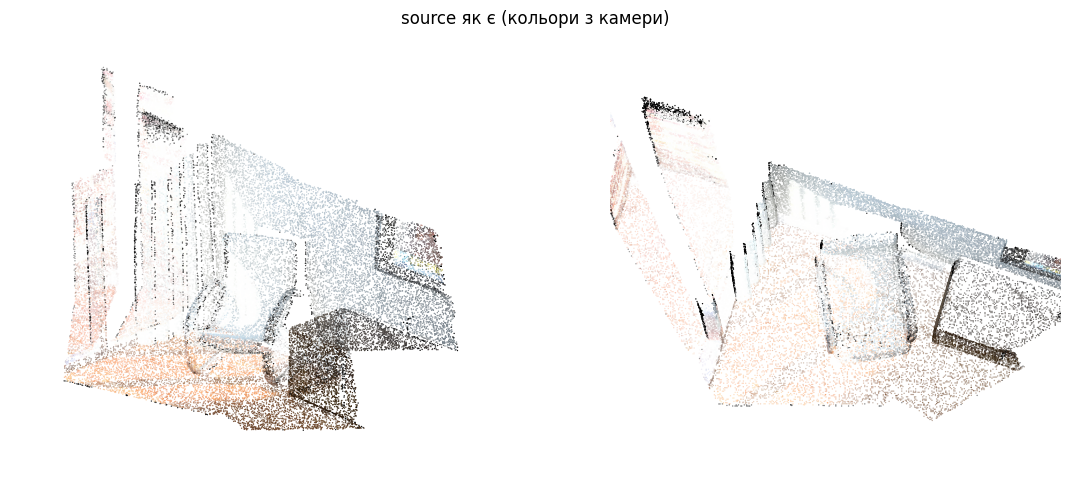

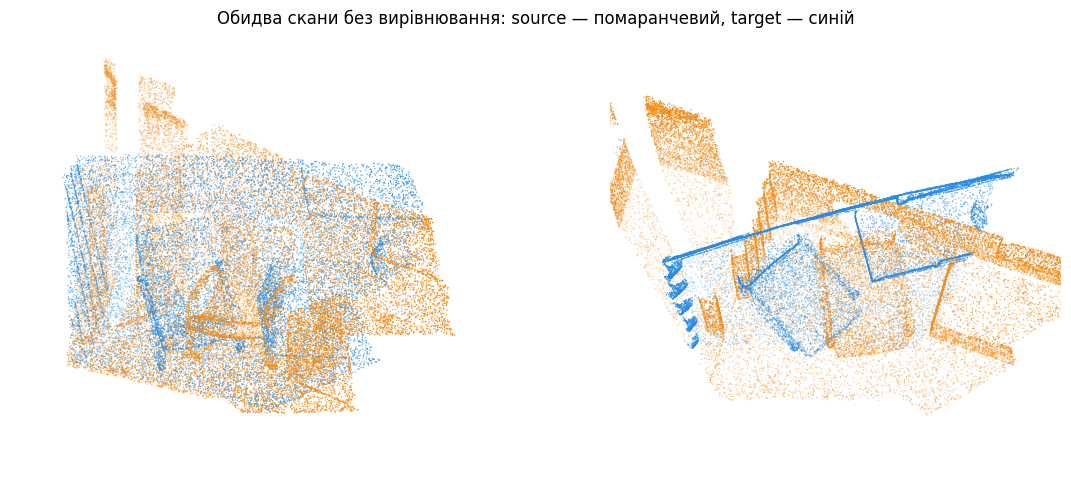

In [90]:
paths = o3d.data.DemoICPPointClouds().paths
source, target = o3d.io.read_point_cloud(paths[0]), o3d.io.read_point_cloud(paths[1])
for name, c in [('source', source), ('target', target)]:
    size = c.get_axis_aligned_bounding_box().get_extent()
    print(f'{name}: {len(c.points):>7,} точок, габарити {size[0]:.1f} × {size[1]:.1f} × {size[2]:.1f} м')

ORANGE, BLUE = [0.95, 0.55, 0.1], [0.15, 0.55, 0.9]
show_cloud(source, title='source як є (кольори з камери)')
show_cloud(paint(source, ORANGE), paint(target, BLUE), title='Обидва скани без вирівнювання: source — помаранчевий, target — синій')

## 2.2 · Проріджування вокселями (≈ 10 хв)
200 тисяч точок — забагато для швидкого ICP, а сусідні точки часто стоять за кілька міліметрів одна від одної. **Voxel downsampling** ділить простір на кубики (вокселі) зі стороною `voxel_size` і з усіх точок в одному кубику лишає одну (слайд «Підготовка хмари: вокселі й нормалі»).

**TODO 2.2.** Допишіть виклик проріджування, подивіться на кількість точок для різних розмірів і виберіть `VOXEL`, за якого кімната ще впізнавана, а точок у `source` 15–60 тисяч.

*Підказка:* `cloud.voxel_down_sample(voxel_size=...)`

voxel 0.01 м →  95,354 точок


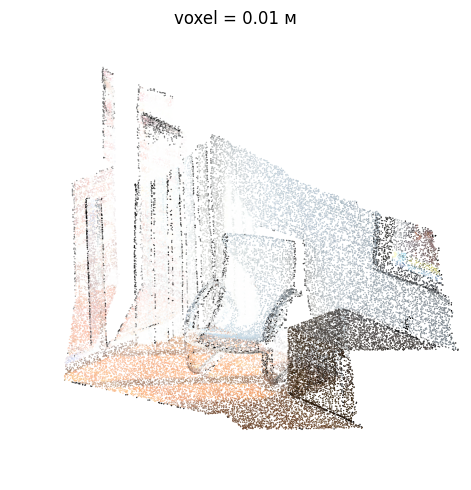

voxel 0.02 м →  27,211 точок


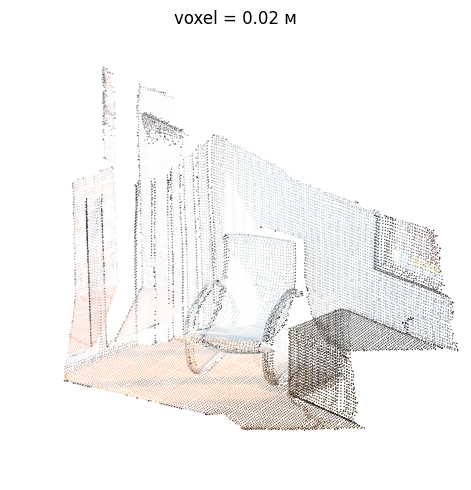

voxel 0.05 м →   4,760 точок


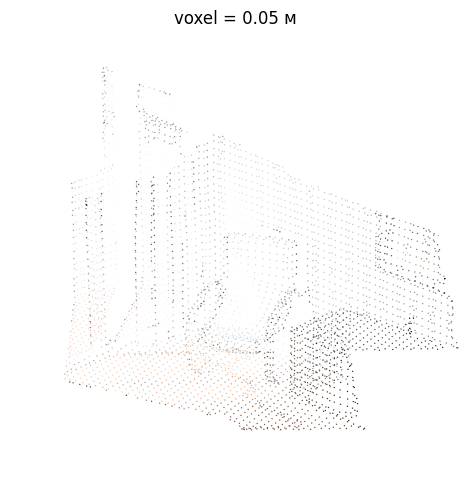

voxel  0.1 м →   1,301 точок


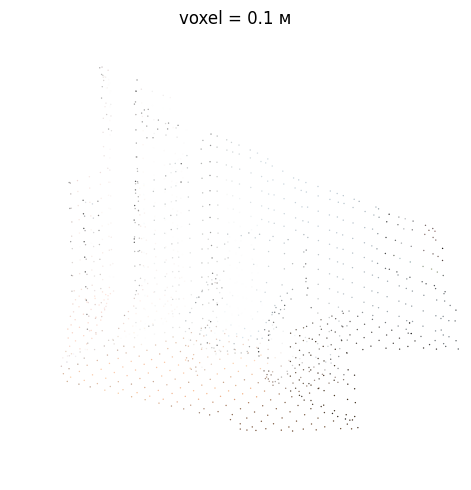

In [93]:
for v in [0.01, 0.02, 0.05, 0.1]:
    # TODO 2.2: проріджена копія source з розміром вокселя v
    small = source.voxel_down_sample(voxel_size=v)  
    print(f'voxel {v:>4} м → {len(small.points):>7,} точок')
    show_cloud(small, title=f'voxel = {v} м', views=((20, -60),))

In [95]:
VOXEL = 0.02   # TODO 2.2: ваш вибір, м
src, tgt = source.voxel_down_sample(VOXEL), target.voxel_down_sample(VOXEL)
for c in (src, tgt):                             # нормалі потрібні варіанту ICP «точка-площина»
    c.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=2 * VOXEL, max_nn=30))
check(15_000 <= len(src.points) <= 60_000, f'VOXEL = {VOXEL} м, {len(src.points):,} точок',
      f'{len(src.points):,} точок — оберіть VOXEL так, щоб лишилось 15–60 тис.')

✅ VOXEL = 0.02 м, 27,211 точок


True

## 2.3 · ICP з початковим наближенням (≈ 15 хв)
ICP на кожній ітерації зіставляє кожну точку `source` з найближчою точкою `target` (якщо вона ближче за `ICP_DIST`), рахує поворот і зсув, що зводять пари докупи, і повторює. Він точний, **але тільки якщо стартувати вже майже з правильного положення**.

У реальній системі грубе наближення дає інший сенсор: IMU, колісна одометрія або модель сталої швидкості (слайд «Методи мінімізації помилки накопичення (дрифту)», блок Sensor Fusion). Тут його вже дано як `T_INIT`.

Як читати результат:
- `fitness` — частка точок `source`, які знайшли пару ближче за поріг (1.0 = усі);
- `inlier_rmse` — середня відстань між такими парами, м (менше — краще).

`fitness` залежить від порогу: з порогом 30 см «пару» знайде майже кожна точка. Тому якість **завжди міряємо з одним порогом 2 см**, хоч би яким був `ICP_DIST`.

**TODO 2.3.** Запустіть ICP від `T_INIT` і підберіть `ICP_DIST` так, щоб **fitness ≥ 0.55 і rmse ≤ 10 мм** (при порозі 2 см).

*Підказка:* `REG.registration_icp(src, tgt, ICP_DIST, T_INIT, REG.TransformationEstimationPointToPlane())` повертає результат з полями `.transformation`, `.fitness`, `.inlier_rmse`. Пробуйте `ICP_DIST` від 0.01 до 0.3.

In [98]:
REG = o3d.pipelines.registration
T_INIT = np.array([[0.862, 0.011, -0.507, 0.5],     # грубе наближення «від IMU»
                   [-0.139, 0.967, -0.215, 0.7],
                   [0.487, 0.255, 0.835, -1.4],
                   [0.0, 0.0, 0.0, 1.0]])


def placed(cloud, T):
    c = o3d.geometry.PointCloud(cloud); c.transform(T); return c


def quality(T):
    return REG.evaluate_registration(src, tgt, 0.02, T)       # якість при фіксованому порозі 2 см

старт T_INIT: fitness = 0.16, rmse = 12.9 мм
після ICP:    fitness = 0.62, rmse = 9.6 мм
ICP виправив старт на 2.4° і 20 см


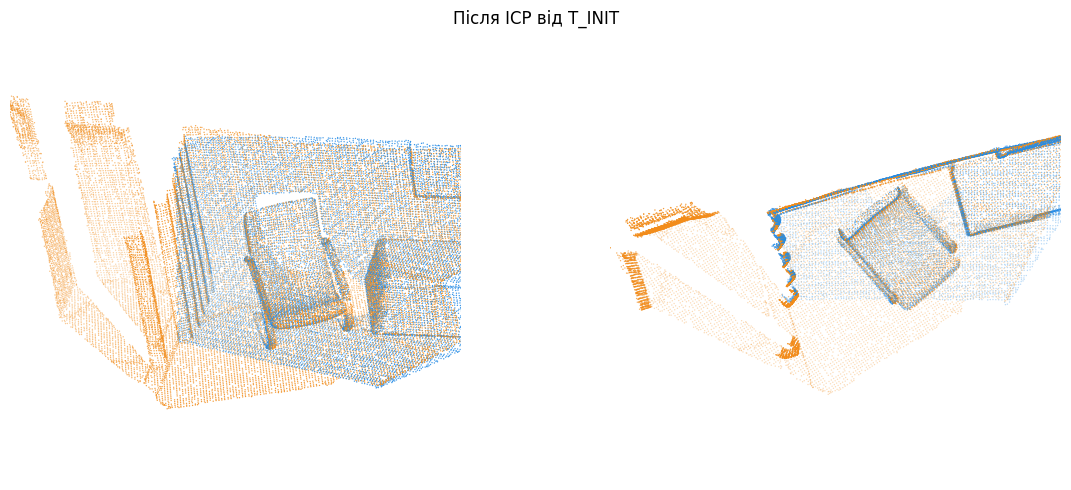

✅ скани зшито


True

In [100]:
ICP_DIST = 0.05   # TODO 2.3: м
 # TODO 2.3: ICP від T_INIT
fine = REG.registration_icp(
    src,
    tgt,
    ICP_DIST,
    T_INIT,
    REG.TransformationEstimationPointToPlane()
)

q0, q = quality(T_INIT), quality(fine.transformation)
dT = np.linalg.inv(T_INIT) @ fine.transformation
print(f'старт T_INIT: fitness = {q0.fitness:.2f}, rmse = {q0.inlier_rmse * 1000:.1f} мм')
print(f'після ICP:    fitness = {q.fitness:.2f}, rmse = {q.inlier_rmse * 1000:.1f} мм')
print(f'ICP виправив старт на {rot_deg(dT[:3, :3]):.1f}° і {np.linalg.norm(dT[:3, 3]) * 100:.0f} см')
show_cloud(paint(placed(src, fine.transformation), ORANGE), paint(tgt, BLUE), title='Після ICP від T_INIT')
check(q.fitness >= 0.55 and q.inlier_rmse <= 0.010, 'скани зшито',
      f'fitness {q.fitness:.2f} (треба ≥ 0.55), rmse {q.inlier_rmse * 1000:.1f} мм (треба ≤ 10) — змініть ICP_DIST')

# ПРИ
# ICP_DIST = 0.02

результат:
старт T_INIT: fitness = 0.16, rmse = 12.9 мм
після ICP:    fitness = 0.34, rmse = 10.2 мм
ICP виправив старт на 2.6° і 19 см

fitness 0.34 (треба ≥ 0.55), rmse 10.2 мм (треба ≤ 10) — змініть ICP_DIST

fitness ≥ 0.55 — щонайменше 55% точок src знаходять відповідності в межах 2 см.
inlier_rmse ≤ 10 мм — середньоквадратична похибка відстаней між відповідними точками не перевищує 1 см.

## 2.4 · А якщо старту немає? (≈ 5 хв)
**TODO 2.4.** Запустіть той самий ICP з тим самим `ICP_DIST`, але від одиничної матриці `np.eye(4)` («скани вже на місці»). Порівняйте fitness і картинку з кроком 2.3.

ICP від eye(4): fitness = 0.14, rmse = 11.6 мм   (від T_INIT було 0.62)


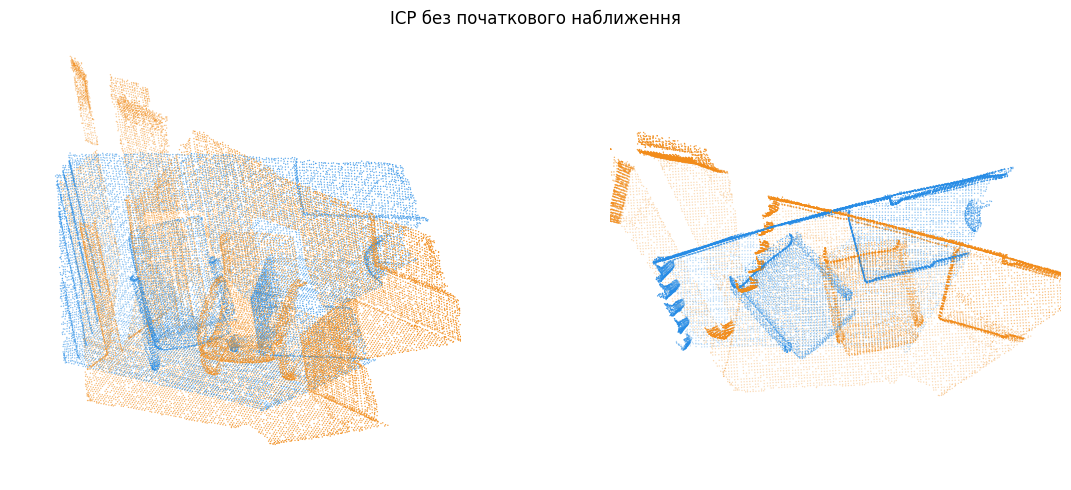

✅ ICP без старту помітно гірший — так і має бути


True

In [104]:
# TODO 2.4: ICP від np.eye(4)
bad = REG.registration_icp(
    src,
    tgt,
    ICP_DIST,
    np.eye(4),
    REG.TransformationEstimationPointToPlane()
)

q_bad = quality(bad.transformation)
print(f'ICP від eye(4): fitness = {q_bad.fitness:.2f}, rmse = {q_bad.inlier_rmse * 1000:.1f} мм   (від T_INIT було {q.fitness:.2f})')
show_cloud(paint(placed(src, bad.transformation), ORANGE), paint(tgt, BLUE), title='ICP без початкового наближення')
check(bad is not None and q_bad.fitness < q.fitness, 'ICP без старту помітно гірший — так і має бути',
      'ICP від eye(4) не гірший за ICP від T_INIT — перевірте, що стартуєте саме з np.eye(4)')

## 2.5 · Експеримент: поріг ICP_DIST (≈ 5 хв, код готовий)
Та сама пара сканів, різні пороги, два старти. У клітинках — fitness при порозі 2 см (≥ 0.55 означає, що зшито). Запустіть і подивіться. Таблиця знадобиться для питання 3.3.

In [107]:
print(f"{'ICP_DIST, м':>12} │ {'від T_INIT':>10} │ {'від eye(4)':>10}")
for d in [0.01, 0.02, 0.05, 0.1, 0.3]:
    row = [quality(REG.registration_icp(src, tgt, d, T0, REG.TransformationEstimationPointToPlane()).transformation).fitness
           for T0 in (T_INIT, np.eye(4))]
    print(f'{d:>12} │ {row[0]:>10.2f} │ {row[1]:>10.2f}')

 ICP_DIST, м │ від T_INIT │ від eye(4)
        0.01 │       0.17 │       0.04
        0.02 │       0.34 │       0.05
        0.05 │       0.62 │       0.14
         0.1 │       0.63 │       0.14
         0.3 │       0.48 │       0.48


## 2.6 · Зшита хмара (≈ 2 хв, код готовий)

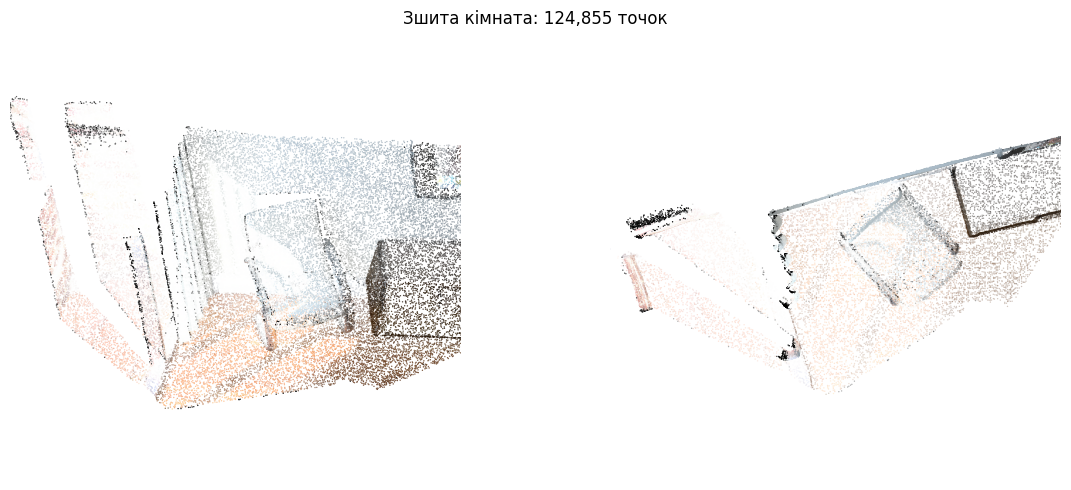

✅ outputs/room_merged.ply збережено


True

In [110]:
merged = (placed(source, fine.transformation) + target).voxel_down_sample(VOXEL / 2)
o3d.io.write_point_cloud(str(OUT_DIR / 'room_merged.ply'), merged)
show_cloud(merged, title=f'Зшита кімната: {len(merged.points):,} точок')
check((OUT_DIR / 'room_merged.ply').exists(), 'outputs/room_merged.ply збережено', 'файл не збережено')

Щоб покрутити результат, відкрийте `outputs/room_merged.ply` у будь-якому 3D-переглядачі (MeshLab, Blender, «3D Viewer» у Windows) або виконайте `o3d.visualization.draw_geometries([merged])`.

In [115]:
merged = o3d.io.read_point_cloud("outputs/room_merged.ply")

print("Кількість точок:", len(merged.points))

o3d.visualization.draw_geometries(
    [merged],
    window_name="Room merged",
    width=1200,
    height=800
)

Кількість точок: 124855


# 3 · Питання (≈ 10 хв)
Відповідайте своїми словами, по 1–3 речення. Формули не потрібні.

**3.1.** За таблицею з кроку 1.6: як змінюються кількість збігів і частка інлаєрів зі зростанням порогу ratio? Чому з RANSAC поворот майже не псується, а метод 8 точок без RANSAC при 0.9–1.0 «ламається»? (слайд «RANSAC проти найменших квадратів»)

✍️ Зі зростанням порогу ratio кількість збігів також збільшується, а частка інлаєрів зменшується тому що збільшується кількість неправильних збігів.
 
RANSAC оцінює модель багато разів. модель отримує пріорітет якщо узгоджується з великою кількістю інлаєрів. Тому неправильні збіги не погіршують оцінку повороту.
Метод 8 точок без RANSAC при 0.9–1.0 «ламається» тому що, для оцінки використовуються всі дані. при ratio 0.9–1.0 - у вибарці може бути багато хибних пар, які спотворюють оцінку моделі, і як наслідок створюється неправильний поворот і перенесення.

**3.2.** `recoverPose` повернув зсув довжиною 1, а справжній — близько 15 см. Чому монокулярна оцінка не може дати метри? Чим цей масштаб отримали б на дроні? (слайди «Проблема масштабу в монокулярній VO» і «Як вирішують проблему масштабу на практиці?»)

✍️ тому що одна камера дає тільки геометрію руху без масштабу. на дроні потрібно додатково використовувати дані з акселерометра і гіросткопа, дані GNSS, дальномір, стереобазу.

з відповіді ментора: Чому немає масштабу: якщо збільшити сцену і зсув камери в k разів, зображення буде точнісінько таким самим. Тому з однієї камери масштаб не визначити в принципі.

**3.3.**  Чому ICP від eye(4) не зшив скани, а від T_INIT зшив? Чому завеликий ICP_DIST (0.3 м) теж погіршує результат, навіть зі стартом T_INIT? (таблиця 2.5, слайди «ICP: як це працює» і «ICP: поріг відповідностей і метрики»)

✍️ в старті з T_INIT початкове перетворення вже приблизно суміщає скани, і ІСР знаходить більше відповідностей. а при старті ICP від `eye(4)` - маємо ситуацію коли точки двох сканів далеко одна від одної, тому ICP в цьому випадку шукає відповідносns біля неправильних позицій

Чому завеликий `ICP_DIST` (0.3 м) теж погіршує результат, навіть зі стартом `T_INIT`? (таблиця 2.5, слайди «ICP: як це працює» і «ICP: поріг відповідностей і метрики»)
при ICP_DIST = 0.3 алгоритм приймає більшу кількість хибні пари, що і впливає на результат, а при ICP_DIST = 0.05 - відкине ці хибні пари.

з відповіді ментора:  Ключова ідея — ICP збігається лише локально: найближча точка є справжньою парою, тільки коли хмари вже майже накладені. Від eye(4) пари хибні, і ICP застрягає в локальному мінімумі.

**3.4.** Уявіть, що сканів не 2, а 50: ви обійшли весь будинок і зшиваєте кожен скан з попереднім (1→0, 2→1, 3→2, …). Кожне зшивання має маленьку похибку. Що станеться з моделлю, коли ви повернетеся до першої кімнати? Як цю проблему вирішує SLAM? (слайди «Дрейф: чому одометрії ніколи не достатньо», «Loop closure (замикання петлі)» і «Інтеграція обмежень замикання циклу»)

з відповіді ментора: Опишіть механізм SLAM. Система розпізнає знайоме місце (loop closure), додає в граф поз обмеження «поточний скан = перший», а глобальна оптимізація розподіляє накопичену похибку по всій траєкторії. Що буде з моделлю без цього: петля не замкнеться, і перша кімната з'явиться двічі, зі зсувом.

✍️ ці маленькі похибки накопичуються, і новий скан 1-шої кімнати може не збігтися з початковим. 
а slam також оцінює траекторію руху і карту, враховуючи час, і при новому скані 1-шої кімнати slam зможе переоцінити позиції.

## Бонус (за бажанням) 
- **Великий поворот.** Повторіть частину 1 для кадрів `A, B = 2, 4` (поворот ≈ 30°). Скільки збігів лишилось і як змінилась похибка?
- **SIFT замість ORB.** У кроці 1.2 використайте `cv2.SIFT_create(2000)`, а в 1.3 — `cv2.BFMatcher(cv2.NORM_L2)`. Чи стала оцінка точнішою? Чого це коштувало за часом?
- **Лідар з авто.** Завантажте KITTI (`python tools/fetch_kitti.py`) і запустіть `kiss_icp_pipeline --dataloader kitti --sequence 00 --n-scans 300 artifacts/kitti` (на Windows консольна команда падає на символьному посиланні — викличте KISS-ICP з Python, як у demo3 заняття). Порівняйте траєкторію з GT: `python lessons/03-odometry-slam/lesson03_demo1_kitti_rerun.py --frames 300 --est-poses <результат>.txt`.